# I.5 — Coordination network of Telegram channels ([A2] method)

**Objective (brief I.5).** Find, without supervision, groups of channels that act in a synchronised way, by
transposing the coordination-network method of Pacheco et al. [A2] to Telegram pump channels:

1. **Traits.** A trait is a pair $j=(c,\lfloor\tau/\Delta\rfloor)$: a coin and a time bucket of length $\Delta$.
   Two channels share a trait when they pump the same coin in the same bucket.
2. **Bipartite matrix.** Channels $\times$ traits, weighted by TF-IDF:
   $A_{uj}=\mathrm{tf}_{uj}\,\log\!\big(|\mathcal U|/\mathrm{df}_j\big)$, where $\mathrm{tf}_{uj}$ is the number of
   times channel $u$ exhibits trait $j$ and $\mathrm{df}_j$ the number of channels exhibiting it. Rare shared traits
   weigh more than traits shared by everyone.
3. **Projection.** Channel–channel weights $W_{uv}=\cos(A_{u\cdot},A_{v\cdot})$.
4. **Filtering.** Keep only the edges above the 99.5 % quantile of the non-zero weights.
5. **Communities.** Louvain algorithm [6], which greedily maximises the modularity
   $$Q=\frac{1}{2m}\sum_{u,v}\Big(W_{uv}-\frac{k_uk_v}{2m}\Big)\mathbf 1\{g_u=g_v\},$$
   with $k_u=\sum_v W_{uv}$ the weighted degree and $2m=\sum_u k_u$.
6. **Null model.** Pump times are permuted across rows (each channel keeps its coins and its number of pumps but
   loses its timing), 1 000 times in the full run. Each edge receives a Monte-Carlo p-value
   $\hat p_{uv}=(1+\#\{b:W^{(b)}_{uv}\ge W_{uv}\})/(B+1)$, and the modularity a null distribution.

We then discuss the sensitivity to $\Delta$ and to the threshold, and compare the communities with the
`session_id` column of the log.

In [1]:
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from scipy import sparse
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

from pnd_paper import settings
from pnd_paper import stats as S
from pnd_paper.data import pd_log
from pnd_paper.report import Reporter, md, show, close, SERIES

settings.seed_everything()
R = Reporter("I5_coordination_network")
B = settings.SIZES.null_draws
log = pd_log.load_pd_log()
log["channel"] = log.channel_id.map(pd_log.channel_labels(log.channel_id))
channels = np.array(sorted(log.channel.unique()))
md(f"{len(log)} rows, $|\\mathcal U|={len(channels)}$ channels. Null-model draws: **B = {B}** "
   f"({'QUICK' if settings.QUICK else 'FULL'} run).")

1335 rows, $|\mathcal U|=108$ channels. Null-model draws: **B = 200** (QUICK run).

In [2]:
def similarity(df, delta):
    """Cosine similarity matrix of the channel x trait TF-IDF matrix for bucket length delta."""
    bucket = (df.timestamp.astype("int64") // int(pd.Timedelta(delta).value)).astype(str)
    trait = df.coin + "|" + bucket
    u = pd.Categorical(df.channel, categories=channels).codes
    tcodes, _ = pd.factorize(trait)
    tf = sparse.csr_matrix((np.ones(len(df)), (u, tcodes)), shape=(len(channels), tcodes.max() + 1))
    tf.sum_duplicates()
    dfj = np.asarray((tf > 0).sum(axis=0)).ravel()
    idf = np.log(len(channels) / dfj)
    A = tf @ sparse.diags(idf)
    norms = np.sqrt(np.asarray(A.multiply(A).sum(axis=1)).ravel())
    norms[norms == 0] = 1.0
    An = sparse.diags(1 / norms) @ A
    W = (An @ An.T).toarray()
    np.fill_diagonal(W, 0.0)
    return W


def graph_from(W, q):
    iu = np.triu_indices_from(W, 1)
    w = W[iu]
    nz = w[w > 0]
    thr = np.quantile(nz, q) if len(nz) else np.inf
    G = nx.Graph()
    G.add_nodes_from(range(len(W)))
    for a, b, x in zip(iu[0], iu[1], w):
        if x > 0 and x >= thr:
            G.add_edge(int(a), int(b), weight=float(x))
    G.remove_nodes_from([n for n in list(G.nodes) if G.degree(n) == 0])
    return G, thr


def louvain(G, seed=settings.SEED):
    if G.number_of_edges() == 0:
        return [], np.nan
    comms = nx.community.louvain_communities(G, weight="weight", seed=seed)
    return comms, nx.community.modularity(G, comms, weight="weight")

## 1. Network for $\Delta=1$ hour, threshold 99.5 %

In [3]:
DELTA, Q = "1h", 0.995
W = similarity(log, DELTA)
G, thr = graph_from(W, Q)
comms, mod = louvain(G)
iu = np.triu_indices_from(W, 1)
nz = (W[iu] > 0).sum()
md(f"Pairs of channels sharing at least one trait: **{nz}** of {len(iu[0])} ({nz / len(iu[0]):.1%}). "
   f"Threshold (99.5 % quantile of non-zero weights): $W\\ge{thr:.3f}$, which keeps **{G.number_of_edges()} edges** "
   f"between **{G.number_of_nodes()} channels**. Louvain finds **{len(comms)} communities** with modularity "
   f"$Q={mod:.3f}$.")

Pairs of channels sharing at least one trait: **490** of 5778 (8.5%). Threshold (99.5 % quantile of non-zero weights): $W\ge0.906$, which keeps **3 edges** between **6 channels**. Louvain finds **3 communities** with modularity $Q=0.666$.

Because only a few dozen pairs survive the 99.5 % filter, we also analyse the network filtered at the 95 % quantile,
which keeps more structure while still discarding most weak coincidences.

In [4]:
G95, thr95 = graph_from(W, 0.95)
comms95, mod95 = louvain(G95)
md(f"At 95 %: $W\\ge{thr95:.3f}$, {G95.number_of_edges()} edges, {G95.number_of_nodes()} channels, "
   f"{len(comms95)} communities, $Q={mod95:.3f}$.")

At 95 %: $W\ge0.648$, 25 edges, 21 channels, 7 communities, $Q=0.465$.

## 2. Null model: permuting pump times

Under $H_0$ "channels choose *when* to pump independently of each other", shuffling the timestamps across rows
preserves each channel's coins and activity but destroys synchronisation. For every draw we recompute $W^{(b)}$,
the number of non-zero pairs, and the modularity of the network filtered at the same quantile.

,observed,null mean,null sd,p_hat
statistic,,,,
non-zero pairs,490,17.19,4.145,0.004975
modularity Q (99.5%),0.6661,1.221e-17,3.482e-17,0.004975
modularity Q (95%),0.4653,0.08673,0.1822,0.1343


Edge-level test: 487 of 490 non-zero edges are significant at FDR 5 % (Benjamini–Hochberg on $\hat p_{uv}$; the smallest attainable $\hat p$ is $1/(B+1)=0.0050$). Under the null, channels share a trait for 17 pairs on average versus 490 observed: $\hat p=0.0050$ → reject $H_0$ at $\alpha=0.05$.

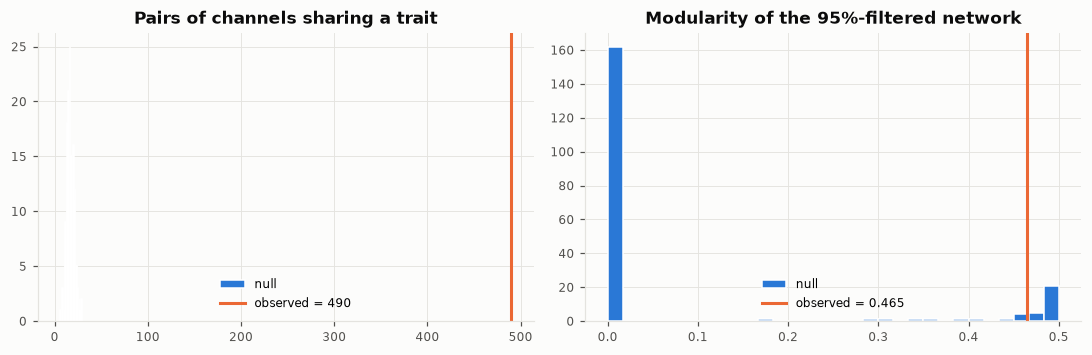

In [5]:
rng = np.random.default_rng(settings.SEED)
null_W = np.empty((B, len(iu[0])))
null_nz, null_Q, null_Q95 = np.empty(B), np.empty(B), np.empty(B)
for b in range(B):
    perm = log.assign(timestamp=log.timestamp.values[rng.permutation(len(log))])
    Wb = similarity(perm, DELTA)
    null_W[b] = Wb[iu]
    null_nz[b] = (Wb[iu] > 0).sum()
    null_Q[b] = louvain(graph_from(Wb, Q)[0], seed=b)[1]
    null_Q95[b] = louvain(graph_from(Wb, 0.95)[0], seed=b)[1]

obs = W[iu]
edge_p = (1 + (null_W >= obs[None, :]).sum(axis=0)) / (B + 1)
edge_q = S.benjamini_hochberg(edge_p[obs > 0])
null_tab = pd.DataFrame({
    "statistic": ["non-zero pairs", "modularity Q (99.5%)", "modularity Q (95%)"],
    "observed": [nz, mod, mod95],
    "null mean": [null_nz.mean(), np.nanmean(null_Q), np.nanmean(null_Q95)],
    "null sd": [null_nz.std(ddof=1), np.nanstd(null_Q, ddof=1), np.nanstd(null_Q95, ddof=1)],
    "p_hat": [S.monte_carlo_p(nz, null_nz), S.monte_carlo_p(mod, null_Q[np.isfinite(null_Q)]),
              S.monte_carlo_p(mod95, null_Q95[np.isfinite(null_Q95)])],
}).set_index("statistic")
R.table(null_tab, "null_model")
show(null_tab)
sig = int((edge_q < 0.05).sum())
md(f"Edge-level test: {sig} of {int((obs > 0).sum())} non-zero edges are significant at FDR 5 % "
   f"(Benjamini–Hochberg on $\\hat p_{{uv}}$; the smallest attainable $\\hat p$ is $1/(B+1)={1 / (B + 1):.4f}$). "
   f"Under the null, channels share a trait for {null_nz.mean():.0f} pairs on average versus {nz} observed: "
   f"$\\hat p={S.monte_carlo_p(nz, null_nz):.4f}$ → {S.decision(S.monte_carlo_p(nz, null_nz))}.")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.3))
axes[0].hist(null_nz, bins=30, color=SERIES[0], edgecolor="white", label="null")
axes[0].axvline(nz, color=SERIES[1], lw=2, label=f"observed = {nz}")
axes[0].set_title("Pairs of channels sharing a trait")
axes[0].legend()
axes[1].hist(null_Q95[np.isfinite(null_Q95)], bins=30, color=SERIES[0], edgecolor="white", label="null")
axes[1].axvline(mod95, color=SERIES[1], lw=2, label=f"observed = {mod95:.3f}")
axes[1].set_title("Modularity of the 95%-filtered network")
axes[1].legend()
R.fig(fig, "null_model")
close(fig)

## 3. Sensitivity to $\Delta$ and to the threshold

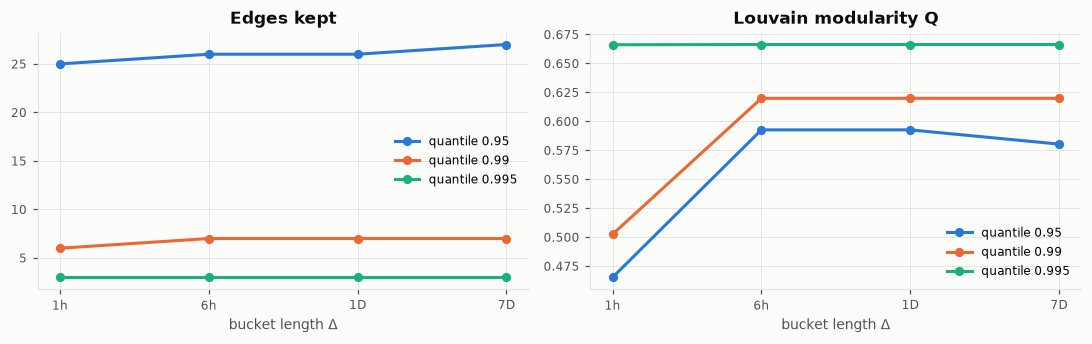

In [6]:
sens = []
for delta in ["1h", "6h", "1D", "7D"]:
    Wd = similarity(log, delta)
    for q in (0.95, 0.99, 0.995):
        Gd, t = graph_from(Wd, q)
        cd, md_ = louvain(Gd)
        sens.append({"Delta": delta, "quantile": q, "non-zero pairs": int((Wd[iu] > 0).sum()), "threshold": t,
                     "edges": Gd.number_of_edges(), "channels": Gd.number_of_nodes(), "communities": len(cd),
                     "modularity": md_, "largest community": max((len(c) for c in cd), default=0)})
sens = pd.DataFrame(sens)
R.table(sens, "sensitivity", index=False)
show(sens.set_index(["Delta", "quantile"]))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for i, q in enumerate((0.95, 0.99, 0.995)):
    s = sens[sens["quantile"] == q]
    axes[0].plot(s.Delta, s.edges, marker="o", color=SERIES[i], label=f"quantile {q}")
    axes[1].plot(s.Delta, s.modularity, marker="o", color=SERIES[i], label=f"quantile {q}")
axes[0].set_title("Edges kept")
axes[1].set_title("Louvain modularity Q")
for a in axes:
    a.set_xlabel(r"bucket length $\Delta$")
    a.legend()
R.fig(fig, "sensitivity")
close(fig)

## 4. Network figure (Δ = 1 h, 95 % filter)

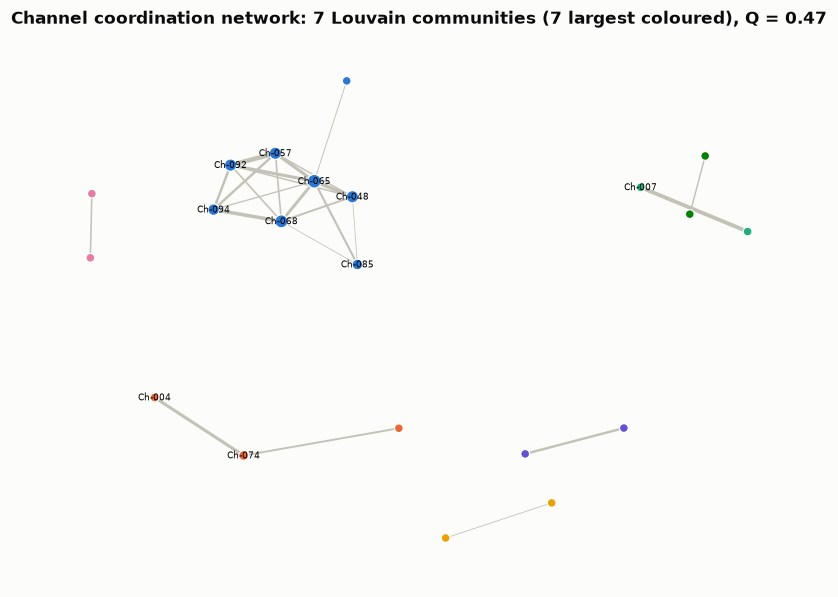

In [7]:
pos = nx.spring_layout(G95, weight="weight", seed=settings.SEED, k=0.6)
order = sorted(comms95, key=len, reverse=True)
color_of = {}
for i, c in enumerate(order):
    for n in c:
        color_of[n] = SERIES[i] if i < 7 else "#b9b8b2"
fig, ax = plt.subplots(figsize=(7.5, 5.5))
ws = np.array([d["weight"] for *_, d in G95.edges(data=True)])
nx.draw_networkx_edges(G95, pos, ax=ax, width=0.5 + 2.5 * (ws - ws.min()) / (np.ptp(ws) + 1e-9), edge_color="#c3c2b7")
nx.draw_networkx_nodes(G95, pos, ax=ax, node_size=[25 + 8 * G95.degree(n) for n in G95.nodes],
                       node_color=[color_of[n] for n in G95.nodes], edgecolors="white", linewidths=0.8)
labels = {n: channels[n] for n in sorted(G95.nodes, key=G95.degree, reverse=True)[:10]}
nx.draw_networkx_labels(G95, pos, labels, font_size=6, ax=ax)
ax.set_title(f"Channel coordination network: {len(order)} Louvain communities (7 largest coloured), Q = {mod95:.2f}")
ax.axis("off")
R.fig(fig, "network")
close(fig)

## 5. Comparison with `session_id`

In the authors' log, `session_id` numbers the **sessions of one channel** (the output of their message-session
aggregation), not a pump shared between channels: the same number in two channels is a coincidence. We verify
this, then compare the communities with the grouping `session_id` was meant to approximate, the **co-pump groups**:
connected components of the graph joining two channels whenever they announced the same coin within the same
hour. Agreement between partitions is measured on the channels present in the network with

* the adjusted Rand index $\mathrm{ARI}=\dfrac{\mathrm{RI}-\mathbb E[\mathrm{RI}]}{\max\mathrm{RI}-\mathbb E[\mathrm{RI}]}$
  (0 for random partitions, 1 for identical ones);
* the normalised mutual information $\mathrm{NMI}=\dfrac{2I(X;Y)}{H(X)+H(Y)}$.

In [8]:
shared = log.groupby("session_id").channel_id.nunique()
same_sid = log[log.session_id.isin(shared[shared > 1].index)]
coin_agree = same_sid.groupby("session_id").coin.nunique().eq(1).mean()
md(f"{(shared > 1).sum()} session ids appear in more than one channel; in only **{coin_agree:.1%}** of them do all "
   "rows name the same coin, so `session_id` is a per-channel counter and cannot by itself identify a coordinated "
   "pump.")

h = log.assign(h=log.timestamp.dt.floor("h"), u=pd.Categorical(log.channel, categories=channels).codes)
pair_counts = {}
for _, g in h.groupby(["coin", "h"]):
    us = sorted(set(g.u))
    for i_, a_ in enumerate(us):
        for b_ in us[i_ + 1:]:
            pair_counts[(a_, b_)] = pair_counts.get((a_, b_), 0) + 1
G1 = nx.Graph()
G1.add_nodes_from(range(len(channels)))
G1.add_edges_from(k for k, v in pair_counts.items() if v >= 1)
giant = max(nx.connected_components(G1), key=len)
md(f"Joining channels that co-announced at least one pump gives a giant component of **{len(giant)}** channels: "
   "relays chain almost every active channel together, so single co-pumps cannot define groups. We therefore define "
   "**repeated co-pump groups** as connected components of the graph joining channels with **at least two** "
   "co-announced pumps, restricted to the channels of the network.")
rows = []
for name, (Gx, cx) in {"99.5% filter": (G, comms), "95% filter": (G95, comms95)}.items():
    nodes = sorted(Gx.nodes)
    G2 = nx.Graph()
    G2.add_nodes_from(nodes)
    G2.add_edges_from(k for k, v in pair_counts.items() if v >= 2 and k[0] in G2 and k[1] in G2)
    grp = {n: i for i, comp in enumerate(nx.connected_components(G2)) for n in comp}
    lab = {n: i for i, c in enumerate(cx) for n in c}
    a = [lab[n] for n in nodes]
    b = [grp[n] for n in nodes]
    sidmode = [log[log.channel == channels[n]].session_id.mode().iloc[0] for n in nodes]
    rows.append({"network": name, "channels": len(nodes), "repeated co-pump groups": len(set(b)),
                 "communities": len(set(a)), "ARI vs co-pump groups": adjusted_rand_score(b, a),
                 "NMI vs co-pump groups": normalized_mutual_info_score(b, a),
                 "ARI vs session_id (modal)": adjusted_rand_score(sidmode, a)})
cmp_tab = pd.DataFrame(rows).set_index("network")
R.table(cmp_tab, "communities_vs_sessions")
show(cmp_tab)

comm_rows = []
for i, c in enumerate(order[:7]):
    sub = log[log.channel.isin(channels[list(c)])]
    comm_rows.append({"community": i + 1, "channels": len(c), "rows": len(sub), "distinct coins": sub.coin.nunique(),
                      "main exchange": sub.exchange.mode().iloc[0],
                      "active from": f"{sub.timestamp.min():%Y-%m}", "active to": f"{sub.timestamp.max():%Y-%m}"})
comm_tab = pd.DataFrame(comm_rows).set_index("community")
R.table(comm_tab, "community_profiles")
show(comm_tab)

276 session ids appear in more than one channel; in only **0.4%** of them do all rows name the same coin, so `session_id` is a per-channel counter and cannot by itself identify a coordinated pump.

Joining channels that co-announced at least one pump gives a giant component of **91** channels: relays chain almost every active channel together, so single co-pumps cannot define groups. We therefore define **repeated co-pump groups** as connected components of the graph joining channels with **at least two** co-announced pumps, restricted to the channels of the network.

,channels,repeated co-pump groups,communities,ARI vs co-pump groups,NMI vs co-pump groups,ARI vs session_id (modal)
network,,,,,,
99.5% filter,6,2,3,0.4444,0.7337,0
95% filter,21,8,7,0.9831,0.9816,0.16


,channels,rows,distinct coins,main exchange,active from,active to
community,,,,,,
1,8,40,9,binance,2020-03,2021-11
2,3,7,3,binance,2019-08,2019-09
3,2,11,5,binance,2019-08,2021-11
4,2,3,2,binance,2019-06,2019-06
5,2,10,5,binance,2019-03,2019-06
6,2,40,17,yobit,2019-01,2019-05
7,2,15,9,binance,2019-05,2021-07


## 6. Interpretation (QUICK run, B = 200)

* **Synchronisation is massive and far beyond chance.** 490 pairs of channels share at least one
  (coin, hour) trait, against about 17 when pump times are shuffled ($\hat p=1/(B+1)$, the smallest value the
  number of draws allows). 487 of the 490 non-zero edges are individually significant at FDR 5 %. Channels do not
  pick their coins and times independently: a large share of pumps are **relayed** or jointly organised.
* **Communities.** At the brief's 99.5 % threshold only 3 edges survive because the projected network is small
  (490 non-zero pairs). The 95 % filter keeps 25 edges between 21 channels, split by Louvain into 7 communities
  ($Q\approx0.47$). The largest groups 8 Binance channels active from 2020 to 2021; one community is a Yobit
  pair active in early 2019.
* **Is the community structure itself significant?** At 95 %, the null modularity is 0.09 on average but highly
  variable, and $\hat p\approx0.13$: the *edges* are significant, but given that few edges are kept, a modularity of
  0.47 is not exceptional. The filtered network is a set of nearly disconnected cliques, and modularity is high
  for any such graph. The communities should be read as "groups of channels that repeatedly relay each other",
  not as a hidden structure beyond pairwise coordination.
* **Sensitivity.** Results barely change with $\Delta$ from 6 hours to 7 days (same communities, $Q\approx0.59$), and
  $\Delta=1$ h loses a few pairs whose announcements differ by more than an hour. The threshold matters much more
  than $\Delta$: 25 edges at 95 %, 6–7 at 99 %, 3 at 99.5 %. The 99.5 % rule of [A2] was designed for networks
  with millions of accounts; with 108 channels a lower quantile is needed to keep any structure.
* **Comparison with `session_id`.** `session_id` is a per-channel session counter (the same id in two channels
  names the same coin in only 0.4 % of cases), so it cannot be compared directly and its ARI with the communities
  is close to 0. Against the grouping it was meant to approximate, groups of channels that co-announced at least
  two pumps, the 95 % communities agree almost perfectly ($\mathrm{ARI}\approx0.98$, $\mathrm{NMI}\approx0.98$).
  The unsupervised network recovers the relay groups without being told about them.

**Limitations.** The null model keeps each channel's coins but breaks the joint timing of *all* pumps, including
genuine market-wide waves (several unrelated channels can pick the same trendy coin in the same day). A null that
preserves the daily popularity of coins would be stricter.